<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta8g%C3%B6rev8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

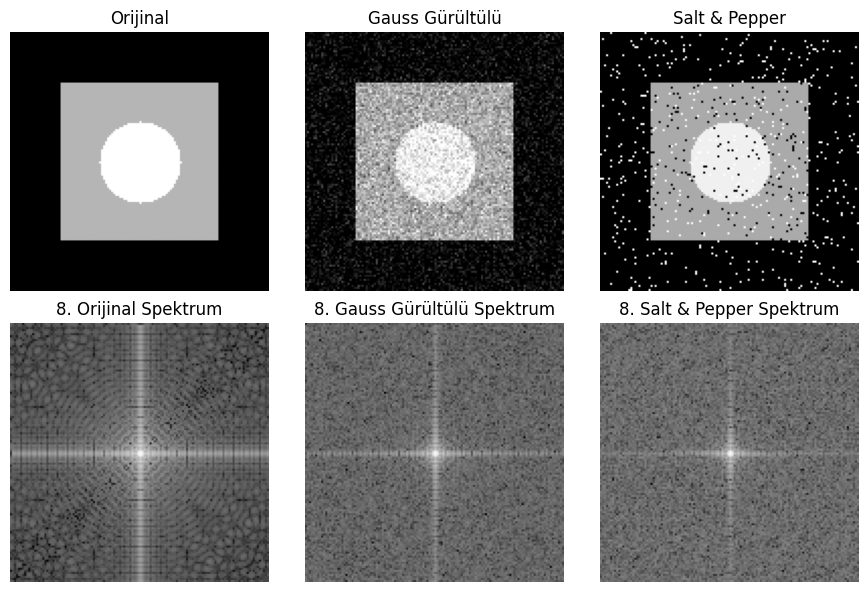

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def gauss_gurultu_ekle(goruntu, oran=0.1, tohum=42):
    rng = np.random.default_rng(tohum)
    sigma = oran * 255.0
    gurultulu = goruntu.astype(np.float64) + rng.normal(0.0, sigma, size=goruntu.shape)
    return np.clip(gurultulu, 0, 255).astype(np.uint8)


def salt_pepper_gurultu_ekle(goruntu, oran=0.05, tohum=42):
    rng = np.random.default_rng(tohum)
    cikti = goruntu.copy()
    olasilik = rng.random(goruntu.shape)
    cikti[olasilik < oran / 2.0] = 0
    cikti[olasilik > 1.0 - oran / 2.0] = 255
    return cikti


def log_spektrum(img):
    F = np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))
    return np.log1p(np.abs(F))


y_idx, x_idx = np.ogrid[:128, :128]
ori = np.zeros((128, 128), dtype=np.uint8)
ori[25:103, 25:103] = 170
ori[(y_idx - 64) ** 2 + (x_idx - 64) ** 2 <= 20 ** 2] = 240

gauss_resim = gauss_gurultu_ekle(ori, oran=0.12)
sp_resim = salt_pepper_gurultu_ekle(ori, oran=0.06)

plt.figure(figsize=(9, 6))
for idx, (baslik, resim) in enumerate(
    [("Orijinal", ori), ("Gauss Gürültülü", gauss_resim), ("Salt & Pepper", sp_resim)],
    start=1,
):
    plt.subplot(2, 3, idx)
    plt.imshow(resim, cmap="gray")
    plt.title(baslik)
    plt.axis("off")

    plt.subplot(2, 3, idx + 3)
    plt.imshow(log_spektrum(resim), cmap="gray")
    plt.title(f"8. {baslik} Spektrum")
    plt.axis("off")

plt.tight_layout()
plt.show()